In [37]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix

# Set visual theme
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("Packages imported successfully.")

Packages imported successfully.


In [38]:
# Load raw data 
df_raw = pd.read_csv("csgo_round_snapshots.csv")

# Filter for beginning of the round snapshots (time left over 100 seconds)
df = df_raw[(df_raw["time_left"] >= 100) & (~df_raw["bomb_planted"])].copy().reset_index(drop=True)

# Define target variable: if CT wins 1, if T wins 0
y = (df["round_winner"] == "CT").astype(int)

# Sum individual grenades into a "total utility" count for each team
utility_keys = ["grenade_flashbang", "grenade_smokegrenade", "grenade_hegrenade", "grenade_incendiarygrenade"]
ct_util_cols = [f"ct_{k}" for k in utility_keys if f"ct_{k}" in df.columns]
t_util_cols = [f"t_{k}" for k in utility_keys if f"t_{k}" in df.columns]

df["ct_total_utility"] = df[ct_util_cols].sum(axis=1)
df["t_total_utility"] = df[t_util_cols].sum(axis=1)

# Sum up rifles for each team
ct_rifles_list = [c for c in ["ct_weapon_m4a4", "ct_weapon_m4a1_s", "ct_weapon_m4a1s", "ct_weapon_aug"] if c in df.columns]
t_rifles_list = [c for c in ["t_weapon_ak47", "t_weapon_sg553"] if c in df.columns]

df["ct_rifles"] = df[ct_rifles_list].sum(axis=1)
df["t_rifles"] = df[t_rifles_list].sum(axis=1)

# Calculate head to head advntages (CT-T)
# + means CT has advantage, - means T has advantage
features = pd.DataFrame(index=df.index)
features["delta_money"] = df["ct_money"] - df["t_money"]
features["delta_health"] = df["ct_health"] - df["t_health"]
features["delta_armor"] = df["ct_armor"] - df["t_armor"]
features["delta_rifles"] = df["ct_rifles"] - df["t_rifles"]
features["delta_awps"] = df.get("ct_weapon_awp", 0) - df.get("t_weapon_awp", 0)
features["delta_utility"] = df["ct_total_utility"] - df["t_total_utility"]
features["delta_smokes"] = df.get("ct_grenade_smokegrenade", 0) - df.get("t_grenade_smokegrenade", 0)
features["delta_flashes"] = df.get("ct_grenade_flashbang", 0) - df.get("t_grenade_flashbang", 0)

# Select necessary primary equipment and utility features for modeling
equip_cols = [
    "delta_money", "delta_armor", "delta_rifles", 
    "delta_awps", "delta_utility", "delta_smokes", "delta_flashes"
]
X_equip = features[equip_cols].copy()

print(f"Data cleaned: {X_equip.shape[0]} early-round snapshots.")
print(f"Baseline CT win rate: {y.mean():.2%}")

Data cleaned: 51618 early-round snapshots.
Baseline CT win rate: 51.38%


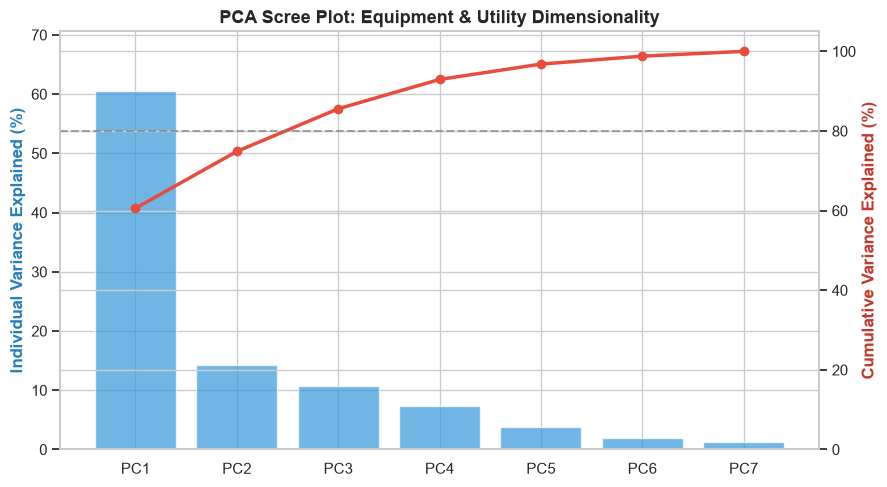

,Explained Variance (%),Cumulative (%)
PC1,60.58,60.58
PC2,14.29,74.87
PC3,10.71,85.58
PC4,7.37,92.94
PC5,3.86,96.80
PC6,2.00,98.80
PC7,1.20,100.00


In [39]:
# PCA
equip_cols = [
    "delta_money", "delta_armor", "delta_rifles", 
    "delta_awps", "delta_utility", "delta_smokes", "delta_flashes"
]
X_equip = features[equip_cols]

# Standardize features to mean of 0 and variance of 1, puts rifles and utility to equal weight
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_equip)

# Run PCA on scaled features to compress related features into principal components
pca = PCA()
X_pca = pca.fit_transform(X_scaled)
pc_names = [f"PC{i+1}" for i in range(X_equip.shape[1])]

# Calculate the variance percentage for each principal component and the cumulative variance
var_ratio = pca.explained_variance_ratio_
cum_var = np.cumsum(var_ratio)

# Scree plot to visualize the variance explained by each principal component
fig, ax1 = plt.subplots(figsize=(9, 5))

# Blue bars show individual variance per component
ax1.bar(pc_names, var_ratio * 100, color="#3498db", alpha=0.7, label="Individual Variance (%)")
ax1.set_ylabel("Individual Variance Explained (%)", color="#2980b9", fontweight="bold")
ax1.set_ylim(0, max(var_ratio * 100) + 10)

# Red line shows cumulative variance explained
ax2 = ax1.twinx()
ax2.plot(pc_names, cum_var * 100, color="#e74c3c", marker="o", linewidth=2.5, label="Cumulative Variance (%)")
ax2.axhline(80, color="gray", linestyle="--", alpha=0.7, label="80% Threshold")
ax2.set_ylabel("Cumulative Variance Explained (%)", color="#c0392b", fontweight="bold")
ax2.set_ylim(0, 105)

plt.title("PCA Scree Plot: Equipment & Utility Dimensionality", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

# Print summary table
pd.DataFrame({
    "Explained Variance (%)": var_ratio * 100,
    "Cumulative (%)": cum_var * 100
}, index=pc_names).round(2)

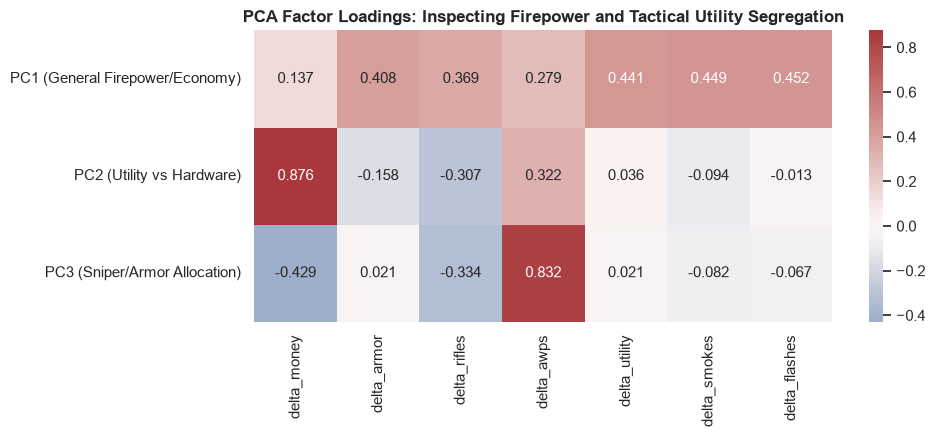

Component Interpretations:
- PC1 captures aggregate financial and hardware dominance (uniform positive weights).
- PC2 isolates tactical grenade density against raw weapon/cash allocation.


In [ ]:
#Create a table for the loadings
loadings = pd.DataFrame(
    pca.components_[:3], 
    columns=equip_cols, 
    index=["PC1 (General Firepower/Economy)", "PC2 (Utility vs Hardware)", "PC3 (Sniper/Armor Allocation)"]
)

# Plot heat map to show features that explain principle components
plt.figure(figsize=(10, 4.5))
sns.heatmap(loadings, annot=True, cmap="vlag", center=0, fmt=".3f", cbar=True)
plt.title("PCA Factor Loadings: Inspecting Firepower and Tactical Utility Segregation", fontweight="bold")
plt.tight_layout()
plt.show()


print("Component Interpretations:")
print("- PC1 captures aggregate financial and hardware dominance (uniform positive weights).")
print("- PC2 isolates tactical grenade density against raw weapon/cash allocation.")

Cluster Profiles Across Tactical Metrics:


,Mean Δ Money,Mean Δ Rifles,Mean Δ AWPs,Mean Δ Utility,CT Win Rate,Count
cluster,,,,,,
0,-6007.75,-0.45,-0.02,0.49,0.44,25191
1,1459.12,1.64,0.77,12.09,0.85,7881
2,-5453.93,-2.99,-0.33,-7.40,0.17,7968
3,9773.43,-0.86,0.95,5.61,0.71,10578


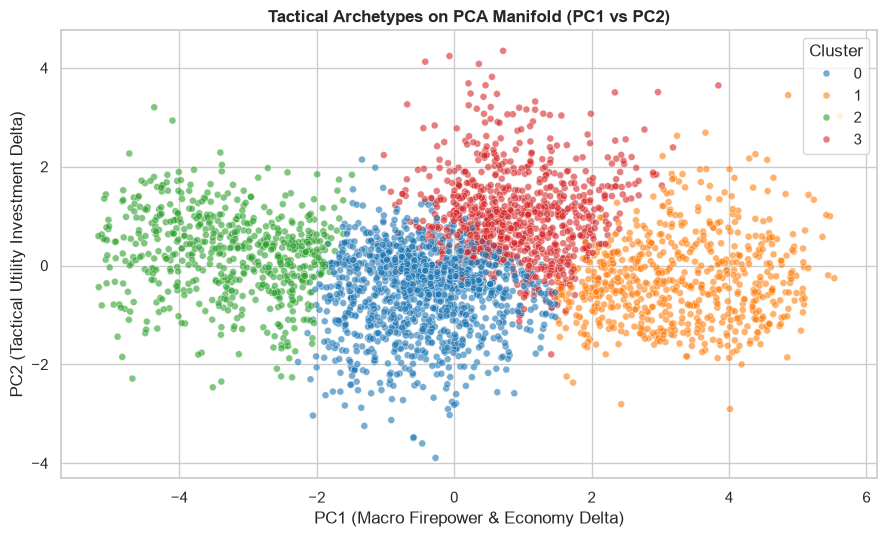

In [ ]:
# K means clustering
# Take only first 3 components
X_pca_sub = X_pca[:, :3]

# Group rounds into 4 clusters from PCA features
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_pca_sub)

# Save cluster assignments and PC coordinates into data frame
features["cluster"] = cluster_labels
features["PC1"] = X_pca_sub[:, 0]
features["PC2"] = X_pca_sub[:, 1]
features["target"] = y

# Calculate average money, rifles, awps, utility, and CT win rate for each cluster
cluster_profile = features.groupby("cluster").agg({
    "delta_money": "mean",
    "delta_rifles": "mean",
    "delta_awps": "mean",
    "delta_utility": "mean",
    "target": ["mean", "count"]
})
cluster_profile.columns = ["Mean Δ Money", "Mean Δ Rifles", "Mean Δ AWPs", "Mean Δ Utility", "CT Win Rate", "Count"]
print("Cluster Profiles Across Tactical Metrics:")
display(cluster_profile.round(2))

# Plot sample of rounds into 2D PCA space with cluster assignments
plt.figure(figsize=(9, 5.5))
sns.scatterplot(
    x="PC1", y="PC2", 
    hue="cluster", 
    palette="tab10", 
    data=features.sample(n=min(4000, len(features)), random_state=42), 
    alpha=0.6, 
    s=25
)
plt.title("Tactical Archetypes on PCA Manifold (PC1 vs PC2)", fontweight="bold")
plt.xlabel("PC1 (Macro Firepower & Economy Delta)")
plt.ylabel("PC2 (Tactical Utility Investment Delta)")
plt.legend(title="Cluster", loc="upper right")
plt.tight_layout()
plt.show()

In [42]:
# Logistic Regression
# Combine top 3 PCA components with cluster assignments for logistic regression
X_model = pd.DataFrame(X_pca_sub, columns=["PC1", "PC2", "PC3"], index=features.index)
cluster_dummies = pd.get_dummies(features["cluster"], prefix="cluster", drop_first=True, dtype=int)
X_model = pd.concat([X_model, cluster_dummies], axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X_model, y, test_size=0.20, random_state=42, stratify=y
)

# Split data 80% for train and 20% test
logit = LogisticRegression(max_iter=1000)
logit.fit(X_train, y_train)

# Train logistic regression model to predict who wins the round
y_pred = logit.predict(X_test)
y_prob = logit.predict_proba(X_test)[:, 1]


# Generate predictions and probabilities on test set
print(classification_report(y_test, y_pred, target_names=["T Win", "CT Win"]))
print(f"Test ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

# Train a second model on standardized raw features to find exact weights
raw_scaler = StandardScaler()
X_raw_scaled = raw_scaler.fit_transform(X_equip)
logit_raw = LogisticRegression(max_iter=1000).fit(X_raw_scaled, y)

# Save standardized coefficients and original standard deviations
coef_df = pd.DataFrame({
    "Feature": equip_cols,
    "Standardized_Beta": logit_raw.coef_[0],
    "Odds_Ratio": np.exp(logit_raw.coef_[0]),
    "Std_Dev": raw_scaler.scale_
})

# Convert coefficients back to unstandardized units to compare money vs grenades
money_beta_per_dollar = coef_df.loc[coef_df["Feature"] == "delta_money", "Standardized_Beta"].values[0] / coef_df.loc[coef_df["Feature"] == "delta_money", "Std_Dev"].values[0]
util_beta_per_nade = coef_df.loc[coef_df["Feature"] == "delta_utility", "Standardized_Beta"].values[0] / coef_df.loc[coef_df["Feature"] == "delta_utility", "Std_Dev"].values[0]

# calc how many dollars of equipment advantage one grenade is worth
dollar_value_of_one_nade = util_beta_per_nade / money_beta_per_dollar

print("\n=== Utility vs. Firepower Exchange Rate ===")
print(f"One tactical grenade equals approximately ${dollar_value_of_one_nade:,.2f} in raw team equipment value.")

              precision    recall  f1-score   support

       T Win       0.69      0.74      0.71      5020
      CT Win       0.74      0.68      0.71      5304

    accuracy                           0.71     10324
   macro avg       0.71      0.71      0.71     10324
weighted avg       0.71      0.71      0.71     10324

Test ROC-AUC Score: 0.7763

=== Utility vs. Firepower Exchange Rate ===
One tactical grenade equals approximately $925.74 in raw team equipment value.


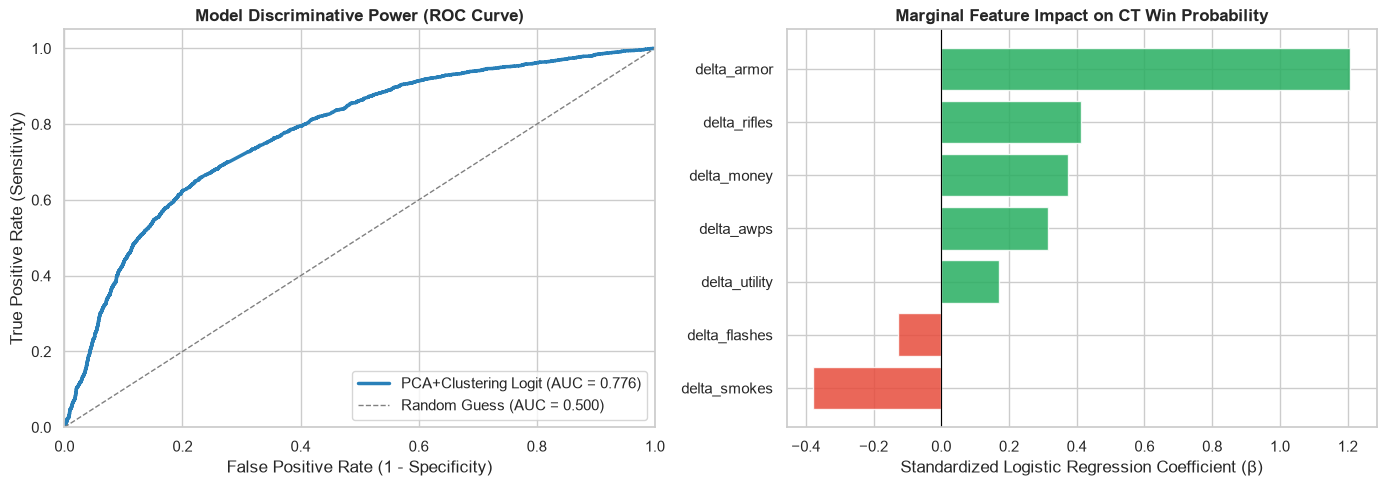

                         PROJECT STATISTICS
Model Accuracy:      71.14%
Model ROC-AUC Score: 0.7763
Confusion Matrix:
[[3736 1284]
 [1696 3608]]
-----------------------------------------------------------------

[Finding 1: Tactical Utility vs. Currency Exchange Rate]
• Empirical Exchange Rate: 1 Tactical Grenade ≈ $925.74 of Equipment Value
  Interpretation: Carrying a full set of team grenades (smokes/flashes)
  offsets approximately $3,702.94 in raw weapon/cash deficit.

[Finding 2: PCA Manifold Structure]
• PC1 successfully isolates macro firepower and team economy.
• PC2 isolates grenade density independent of raw cash reserves,
  confirming utility acts as an orthogonal tactical dimension.

[Finding 3: Tactical Cluster Performance]
• Cluster 0: CT Win Rate = 43.63%, Avg ΔMoney = $-6,008, Avg ΔUtility = +0.49
• Cluster 1: CT Win Rate = 84.82%, Avg ΔMoney = $+1,459, Avg ΔUtility = +12.09
• Cluster 2: CT Win Rate = 16.84%, Avg ΔMoney = $-5,454, Avg ΔUtility = -7.40
• Cluster 3: CT W

In [43]:
# Final Findings
# Compute metrics from outputs above
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc_val = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)
accuracy = (cm[0, 0] + cm[1, 1]) / cm.sum()

# side by side diagnostic plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: ROC Discriminative Curve
ax1.plot(fpr, tpr, color="#2980b9", lw=2.5, label=f"PCA+Clustering Logit (AUC = {auc_val:.3f})")
ax1.plot([0, 1], [0, 1], color="gray", linestyle="--", lw=1, label="Random Guess (AUC = 0.500)")
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel("False Positive Rate (1 - Specificity)")
ax1.set_ylabel("True Positive Rate (Sensitivity)")
ax1.set_title("Model Discriminative Power (ROC Curve)", fontweight="bold")
ax1.legend(loc="lower right")

# Plot B: Feature Impact (green helps CT win, red helps T win)
coef_sorted = coef_df.sort_values(by="Standardized_Beta", ascending=True)
bar_colors = ["#e74c3c" if b < 0 else "#27ae60" for b in coef_sorted["Standardized_Beta"]]

ax2.barh(coef_sorted["Feature"], coef_sorted["Standardized_Beta"], color=bar_colors, alpha=0.85)
ax2.axvline(0, color="black", linestyle="-", lw=0.8)
ax2.set_xlabel("Standardized Logistic Regression Coefficient (β)")
ax2.set_title("Marginal Feature Impact on CT Win Probability", fontweight="bold")

plt.tight_layout()
plt.show()

# 3. Formatted findings
print("=" * 65)
print("                         PROJECT STATISTICS")
print("=" * 65)
print(f"Model Accuracy:      {accuracy:.2%}")
print(f"Model ROC-AUC Score: {auc_val:.4f}")
print(f"Confusion Matrix:\n{cm}")
print("-" * 65)

# Finding 1: dollar value of tactical utility
print("\n[Finding 1: Tactical Utility vs. Currency Exchange Rate]")
print(f"• Empirical Exchange Rate: 1 Tactical Grenade ≈ ${dollar_value_of_one_nade:,.2f} of Equipment Value")
print("  Interpretation: Carrying a full set of team grenades (smokes/flashes)")
print(f"  offsets approximately ${dollar_value_of_one_nade * 4:,.2f} in raw weapon/cash deficit.")

#  Finding 2: PCA findings
print("\n[Finding 2: PCA Manifold Structure]")
print("• PC1 successfully isolates macro firepower and team economy.")
print("• PC2 isolates grenade density independent of raw cash reserves,")
print("  confirming utility acts as an orthogonal tactical dimension.")

# Finding 3: performance of each tactical cluster
print("\n[Finding 3: Tactical Cluster Performance]")
for c_id in sorted(features["cluster"].unique()):
    sub = features[features["cluster"] == c_id]
    print(f"• Cluster {c_id}: CT Win Rate = {sub['target'].mean():.2%}, "
          f"Avg ΔMoney = ${sub['delta_money'].mean():+,.0f}, "
          f"Avg ΔUtility = {sub['delta_utility'].mean():+.2f}")

print("=" * 65)